In [29]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import joblib
import os

import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, Bidirectional, GRU,
    Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.models import Model
import tensorflow.keras.backend as K

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Importing FD002

In [30]:
path_fd2 = "../Dataset/Processed/FD002/"

In [31]:
baseline_comparison_df = pd.read_csv("../Results/comparison_tables/fd002_baseline_comparison.csv")
X_train_fd2 = np.load(os.path.join(path_fd2, "x_train.npy"))
X_test_fd2  = np.load(os.path.join(path_fd2, "x_test.npy"))

y_train_fd2 = np.load(os.path.join(path_fd2, "y_train.npy"))
y_test_fd2  = np.load(os.path.join(path_fd2, "y_test.npy"))

X_val_fd2   = np.load(os.path.join(path_fd2, "x_val.npy"))
y_val_fd2   = np.load(os.path.join(path_fd2, "y_val.npy"))

print(f"Loaded FD002 Pretrained Data: X_train {X_train_fd2.shape}, X_test {X_test_fd2.shape}")


Loaded FD002 Pretrained Data: X_train (36857, 30, 14), X_test (259, 30, 14)


# Importing FD004

In [32]:
path_fd4 = "../Dataset/Raw"

In [33]:
columns = (    
    ['engine_id', 'cycle']    
    + [f'op_setting_{i}' for i in range(1, 4)]    
    + [f'sensor_{i}' for i in range(1, 22)]    
)    


In [34]:
train_fd4 = pd.read_csv(path_fd4 + "/train_FD004.txt", sep=r'\s+', header=None, names=columns)    
test_fd4  = pd.read_csv(path_fd4 + "/test_FD004.txt",  sep=r'\s+', header=None, names=columns)    
rul_fd4   = pd.read_csv(path_fd4 + "/RUL_FD004.txt",   sep=r'\s+', header=None, names=['actual_RUL'])    
rul_fd4['engine_id'] = np.arange(1, len(rul_fd4) + 1)

In [35]:
OP_COLS = ['op_setting_1', 'op_setting_2', 'op_setting_3']
# Load the KMeans model trained on FD002
kmeans_fd2 = joblib.load('../Dataset/Processed/FD002/cluster_model.pkl')

# Apply FD002 clustering to FD004
train_fd4['regime'] = kmeans_fd2.predict(train_fd4[OP_COLS])
test_fd4['regime']  = kmeans_fd2.predict(test_fd4[OP_COLS])

print("FD004 Operating Condition Distribution (Reusing FD002 Clusters):")
print("Train regimes:\n", train_fd4['regime'].value_counts().sort_index())
print("Test regimes:\n", test_fd4['regime'].value_counts().sort_index())

FD004 Operating Condition Distribution (Reusing FD002 Clusters):
Train regimes:
 regime
0    15395
1     9091
2     9139
3     9238
4     9224
5     9162
Name: count, dtype: int64
Test regimes:
 regime
0    10382
1     6254
2     6107
3     6054
4     6185
5     6232
Name: count, dtype: int64


In [36]:
def compute_piecewise_rul(df, cap=125):
    """
    Calculate piecewise linear Remaining Useful Life (RUL) target.
    """
    df = df.copy()
    df['max_cycle'] = df.groupby('engine_id')['cycle'].transform('max')
    df['RUL_uncapped'] = df['max_cycle'] - df['cycle']
    df['RUL'] = df['RUL_uncapped'].clip(upper=cap)
    return df

train_fd4 = compute_piecewise_rul(train_fd4, cap=125)

# Engine-Level 80/20 Train/Validation Split
Split engines before normalization and smoothing to strictly prevent data leakage from validation engines.

In [37]:
np.random.seed(42)
all_engines_fd4 = train_fd4['engine_id'].unique()
train_engines_fd4 = np.random.choice(all_engines_fd4, size=int(0.8 * len(all_engines_fd4)), replace=False)
val_engines_fd4 = np.setdiff1d(all_engines_fd4, train_engines_fd4)

In [38]:
train_split_fd4 = train_fd4[train_fd4['engine_id'].isin(train_engines_fd4)].copy()
val_split_fd4   = train_fd4[train_fd4['engine_id'].isin(val_engines_fd4)].copy()

# Per-Regime Normalization for FD004
Scalers are fitted strictly on the training engines (train_split_fd4) to prevent validation leakage.

In [39]:
SELECTED_SENSORS = [
    'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8',
    'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14',
    'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21'
]

In [40]:
os.makedirs('../Dataset/Processed/FD004', exist_ok=True)
regime_scalers_fd4 = {}

# Fit scalers strictly on training engines to prevent data leakage
for regime in range(6):
    mask = train_split_fd4['regime'] == regime
    scaler = StandardScaler()
    train_split_fd4.loc[mask, SELECTED_SENSORS] = scaler.fit_transform(
        train_split_fd4.loc[mask, SELECTED_SENSORS]
    )
    regime_scalers_fd4[regime] = scaler

# Apply to FD004 validation and test data
for regime in range(6):
    mask_val = val_split_fd4['regime'] == regime
    if mask_val.any():
        val_split_fd4.loc[mask_val, SELECTED_SENSORS] = regime_scalers_fd4[regime].transform(
            val_split_fd4.loc[mask_val, SELECTED_SENSORS]
        )
        
    mask_test = test_fd4['regime'] == regime
    if mask_test.any():
        test_fd4.loc[mask_test, SELECTED_SENSORS] = regime_scalers_fd4[regime].transform(
            test_fd4.loc[mask_test, SELECTED_SENSORS]
        )

joblib.dump(regime_scalers_fd4, '../Dataset/Processed/FD004/regime_scalers.pkl')
print("FD004 per-regime scalers trained on training split and saved.")

FD004 per-regime scalers trained on training split and saved.


C:\Users\muiva\AppData\Local\Temp\ipykernel_23472\4216377442.py:8: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[-0.31864771 -0.91902271 -1.51939772 ...  1.48247731  0.88210231
  1.48247731]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  train_split_fd4.loc[mask, SELECTED_SENSORS] = scaler.fit_transform(
C:\Users\muiva\AppData\Local\Temp\ipykernel_23472\4216377442.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[ 0.2817273  -0.31864771 -0.31864771 ...  2.08285232  1.48247731
  1.48247731]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  val_split_fd4.loc[mask_val, SELECTED_SENSORS] = regime_scalers_fd4[regime].transform(
C:\Users\muiva\AppData\Local\Temp\ipykernel_23472\4216377442.py:23: FutureWarning: Setting an item of incompatible 

# Rolling Mean Smoothing (window=5)

In [41]:
def apply_sensor_smoothing(df, feature_cols=None, window=5):
    """
    Smooth sensor signals across cycles per engine using rolling mean.
    """
    if feature_cols is None:
        feature_cols = SELECTED_SENSORS
    df = df.copy()
    for col in feature_cols:
        df[col] = (
            df.groupby('engine_id')[col]
            .transform(lambda s: s.rolling(window=window, min_periods=1).mean())
        )
    return df

In [42]:
train_split_fd4 = apply_sensor_smoothing(train_split_fd4, SELECTED_SENSORS, window=5)
val_split_fd4   = apply_sensor_smoothing(val_split_fd4,   SELECTED_SENSORS, window=5)
test_fd4        = apply_sensor_smoothing(test_fd4,  SELECTED_SENSORS, window=5)

# Create Sliding Window Sequences (length 30)

In [43]:
def create_training_sequences(df, feature_cols, sequence_length=30):
    """
    Generate sliding-window sequences for training or validation across all engines.
    """
    X, y = [], []
    for engine_id in df['engine_id'].unique():
        engine_subset = df[df['engine_id'] == engine_id].sort_values('cycle')
        features = engine_subset[feature_cols].values
        targets = engine_subset['RUL'].values
        
        # Sliding window
        for end_idx in range(sequence_length - 1, len(engine_subset)):
            start_idx = end_idx - sequence_length + 1
            X.append(features[start_idx:end_idx + 1])
            y.append(targets[end_idx])
            
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

def create_test_sequences(df, rul_df, feature_cols, sequence_length=30):
    """
    Extract the final sliding-window sequence of length 30 for each test engine,
    and pair with ground-truth actual RUL.
    Applies left-padding (repeating first cycle) for engines with cycles < sequence_length,
    preventing silent dropping of short test engines.
    """
    rul_df = rul_df.copy()
    if 'engine_id' not in rul_df.columns:
        rul_df['engine_id'] = np.arange(1, len(rul_df) + 1)

    X_test, y_test, valid_engine_ids = [], [], []
    for engine_id in rul_df['engine_id'].values:
        engine_subset = df[df['engine_id'] == engine_id].sort_values('cycle')
        data = engine_subset[feature_cols].values
        if len(data) >= sequence_length:
            seq = data[-sequence_length:]
        else:
            # Left-pad short engines by repeating the earliest available cycle
            pad_length = sequence_length - len(data)
            pad = np.repeat(data[:1], pad_length, axis=0)
            seq = np.vstack([pad, data])

        actual_rul = rul_df.loc[rul_df['engine_id'] == engine_id, 'actual_RUL'].values[0]
        X_test.append(seq)
        y_test.append(min(actual_rul, 125))  # Evaluate on capped RUL
        valid_engine_ids.append(engine_id)

    return (
        np.array(X_test, dtype=np.float32),
        np.array(y_test, dtype=np.float32),
        np.array(valid_engine_ids, dtype=np.int32)
    )

In [44]:
X_train_fd4, y_train_fd4 = create_training_sequences(train_split_fd4, SELECTED_SENSORS, 30)
X_val_fd4,   y_val_fd4   = create_training_sequences(val_split_fd4,   SELECTED_SENSORS, 30)
X_test_fd4,  y_test_fd4, test_ids_fd4 = create_test_sequences(test_fd4, rul_fd4, SELECTED_SENSORS, 30)

# 5. Save processed data

In [45]:
save_dir_fd4 = '../Dataset/Processed/FD004'
os.makedirs(save_dir_fd4, exist_ok=True)

np.save(os.path.join(save_dir_fd4, 'x_train.npy'), X_train_fd4)
np.save(os.path.join(save_dir_fd4, 'y_train.npy'), y_train_fd4)
np.save(os.path.join(save_dir_fd4, 'x_val.npy'),   X_val_fd4)
np.save(os.path.join(save_dir_fd4, 'y_val.npy'),   y_val_fd4)
np.save(os.path.join(save_dir_fd4, 'x_test.npy'),  X_test_fd4)
np.save(os.path.join(save_dir_fd4, 'y_test.npy'),  y_test_fd4)
np.save(os.path.join(save_dir_fd4, 'test_engine_ids.npy'), test_ids_fd4)

print(f"All FD004 preprocessed arrays saved to {save_dir_fd4}")


All FD004 preprocessed arrays saved to ../Dataset/Processed/FD004


In [46]:
print(f"FD004 Preprocessing Complete:")
print(f"X_train_fd4: {X_train_fd4.shape} | X_val_fd4: {X_val_fd4.shape} | X_test_fd4: {X_test_fd4.shape}")

FD004 Preprocessing Complete:
X_train_fd4: (42725, 30, 14) | X_val_fd4: (11303, 30, 14) | X_test_fd4: (248, 30, 14)


# Experiment A: Transfer Learning (Fine-Tune)

In [47]:
def asymmetric_mse(y_true, y_pred, alpha_early=1.0, alpha_late=2.0):
    """
    Custom loss function penalizing overprediction (late prediction) twice as heavily
    as underprediction (early prediction).
    Overpredicting RUL leads to catastrophic unscheduled in-flight engine failures.
    Underpredicting leads only to harmless premature inspection.
    """
    diff = y_pred - y_true
    weight = tf.where(diff < 0, alpha_early, alpha_late)
    return tf.reduce_mean(weight * tf.square(diff))


In [48]:
os.makedirs('../Models/FD004', exist_ok=True)

# Load pre-trained model from FD002
pretrained_model = tf.keras.models.load_model(
    '../Models/FD002/hybrid_cnn_gru.keras',
    custom_objects={'asymmetric_mse': asymmetric_mse})

In [49]:
# Freeze the CNN feature extractor layers (Conv1D and BatchNormalization)
for layer in pretrained_model.layers:
    if isinstance(layer, (Conv1D, BatchNormalization)) or any(k in layer.name for k in ['conv1d', 'bn']):
        layer.trainable = False


In [50]:
# Verify layer trainable states
for layer in pretrained_model.layers:
    print(f"{layer.name:<20}: trainable={layer.trainable}")

# Compile with a LOWER learning rate (1e-4) for fine-tuning
pretrained_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=asymmetric_mse,
    metrics=['mae']
)

input_sensors       : trainable=True
conv1d_1            : trainable=False
bn_1                : trainable=False
conv1d_2            : trainable=False
bn_2                : trainable=False
bi_gru              : trainable=True
drop_1              : trainable=True
dense_1             : trainable=True
drop_2              : trainable=True
rul_output          : trainable=True


In [51]:
os.makedirs('../Models/FD004', exist_ok=True)
# Fine-tune on FD004 target domain
start_time = time.time()
history_transfer = pretrained_model.fit(
    X_train_fd4, y_train_fd4,
    validation_data=(X_val_fd4, y_val_fd4),
    epochs=50,
    batch_size=64,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6),
        ModelCheckpoint('../Models/FD004/transfer_finetuned.keras', monitor='val_loss', save_best_only=True)
    ],
    verbose=1
)
time_transfer = time.time() - start_time
print(f"Transfer fine-tuning completed in {time_transfer:.1f} seconds.")


Epoch 1/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - loss: 784.2327 - mae: 19.4601 - val_loss: 432.9745 - val_mae: 16.1294 - learning_rate: 1.0000e-04
Epoch 2/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 691.9909 - mae: 18.0327 - val_loss: 392.1892 - val_mae: 15.0591 - learning_rate: 1.0000e-04
Epoch 3/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 663.6032 - mae: 17.6630 - val_loss: 370.3518 - val_mae: 14.3757 - learning_rate: 1.0000e-04
Epoch 4/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 647.9261 - mae: 17.4424 - val_loss: 363.5845 - val_mae: 14.3608 - learning_rate: 1.0000e-04
Epoch 5/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 622.5710 - mae: 17.0909 - val_loss: 341.5947 - val_mae: 13.6393 - learning_rate: 1.0000e-04
Epoch 6/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 606.5997 - mae: 16.8806 - val_loss: 350.4442 - val_mae: 14.0893 - learning_rate: 1.0000e-04
Epoch 7/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 598.0795 - mae: 16.7366 - v

In [52]:
def nasa_score(y_true, y_pred):
    """
    Computes the NASA PHM08 asymmetric scoring function.
    Late predictions (y_pred > y_true) are penalized exponentially higher (e^(d/10)-1)
    than early predictions (y_pred < y_true) which are penalized as (e^(-d/13)-1).
    """
    errors = np.asarray(y_pred).flatten() - np.asarray(y_true).flatten()
    scores = np.where(
        errors < 0,
        np.exp(-errors / 13.0) - 1.0,
        np.exp(errors / 10.0) - 1.0
    )
    return float(np.sum(scores))

def evaluate_model_performance(model, X_te, y_te, name="Model"):
    """
    Computes MAE, RMSE, and NASA Score simultaneously.
    """
    y_pred = model.predict(X_te).flatten()
    mae = float(mean_absolute_error(y_te, y_pred))
    rmse = float(np.sqrt(mean_squared_error(y_te, y_pred)))
    score = nasa_score(y_te, y_pred)
    return {"Model": name, "MAE": round(mae, 2), "RMSE": round(rmse, 2), "NASA Score": round(score, 1)}

In [53]:
# Evaluate fine-tuned model on FD004 test set
y_pred_tf4 = pretrained_model.predict(X_test_fd4).flatten()
metrics_transfer = evaluate_model_performance(pretrained_model, X_test_fd4, y_test_fd4, "Transfer Learning (Hybrid: FD002 -> FD004)")
metrics_transfer['Training Time (s)'] = round(time_transfer, 1)
print("Hybrid Transfer Learning Test Results:", metrics_transfer)


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step 
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Hybrid Transfer Learning Test Results: {'Model': 'Transfer Learning (Hybrid: FD002 -> FD004)', 'MAE': 12.04, 'RMSE': 15.93, 'NASA Score': 978.1, 'Training Time (s)': 225.0}


# Experiment B: Train From Scratch 

In [54]:
def build_hybrid_cnn_gru(input_shape=(30, 14)):
    """
    Builds the state-of-the-art Hybrid CNN-GRU architecture.
    Combines Conv1D feature extraction with Bidirectional GRU sequence modeling.
    """
    inputs = Input(shape=input_shape, name="input_sensors")

    # CNN Feature Extractor (Learns cross-sensor spatial correlations at each cycle)
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same', name="conv1d_1")(inputs)
    x = BatchNormalization(name="bn_1")(x)
    x = Conv1D(32, kernel_size=3, activation='relu', padding='same', name="conv1d_2")(x)
    x = BatchNormalization(name="bn_2")(x)

    # Bidirectional GRU for Temporal Tracking (Captures degradation trend forwards & backwards)
    x = Bidirectional(GRU(32, return_sequences=False), name="bi_gru")(x)
    x = Dropout(0.3, name="drop_1")(x)

    # Dense Regression Head
    x = Dense(32, activation='relu', name="dense_1")(x)
    x = Dropout(0.2, name="drop_2")(x)
    outputs = Dense(1, name="rul_output")(x)

    model = Model(inputs=inputs, outputs=outputs, name="Hybrid_CNN_GRU")
    return model

model_hybrid = build_hybrid_cnn_gru(input_shape=(30, 14))
model_hybrid.summary()

Model: "Hybrid_CNN_GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_sensors (InputLayer)           │ (None, 30, 14)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 30, 64)              │           2,752 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_1 (BatchNormalization)            │ (None, 30, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 30, 32)              │           6,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_2 (BatchNormalization)            │ (None, 30, 32)              │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bi_gru (Bidirectional)               │ (None, 64)                  │          12,672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ drop_1 (Dropout)                     │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ drop_2 (Dropout)                     │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rul_output (Dense)                   │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,097 (94.13 KB)

 Trainable params: 23,905 (93.38 KB)

 Non-trainable params: 192 (768.00 B)

In [55]:
model_scratch = build_hybrid_cnn_gru(input_shape=(30, 14))

model_scratch.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=asymmetric_mse,
    metrics=['mae']
)

In [56]:
start_time = time.time()
history_scratch = model_scratch.fit(
    X_train_fd4, y_train_fd4,
    validation_data=(X_val_fd4, y_val_fd4),
    epochs=100,
    batch_size=64,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6),
        ModelCheckpoint('../Models/FD004/scratch_baseline.keras', monitor='val_loss', save_best_only=True)
    ],
    verbose=1
)


Epoch 1/100
668/668 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - loss: 1839.4081 - mae: 29.7228 - val_loss: 367.5698 - val_mae: 14.4655 - learning_rate: 0.0010
Epoch 2/100
668/668 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 651.4522 - mae: 17.7195 - val_loss: 344.2851 - val_mae: 14.3755 - learning_rate: 0.0010
Epoch 3/100
668/668 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 585.4383 - mae: 16.6762 - val_loss: 296.8094 - val_mae: 12.9736 - learning_rate: 0.0010
Epoch 4/100
668/668 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 534.6777 - mae: 15.9074 - val_loss: 240.1475 - val_mae: 10.9756 - learning_rate: 0.0010
Epoch 5/100
668/668 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 509.8001 - mae: 15.4906 - val_loss: 274.5249 - val_mae: 12.3233 - learning_rate: 0.0010
Epoch 6/100
668/668 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 484.7116 - mae: 15.1164 - val_loss: 262.9617 - val_mae: 11.9740 - learning_rate: 0.0010
Epoch 7/100
668/668 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 462.9243 - mae: 14.7385 - val_loss: 

In [57]:
time_scratch = time.time() - start_time
print(f"Scratch training completed in {time_scratch:.1f} seconds.")

y_pred_sc4 = model_scratch.predict(X_test_fd4).flatten()
metrics_scratch = evaluate_model_performance(model_scratch, X_test_fd4, y_test_fd4, "Trained from Scratch on FD004 (Hybrid)")
metrics_scratch['Training Time (s)'] = round(time_scratch, 1)

fd4_comp_df = pd.DataFrame([metrics_scratch, metrics_transfer])
print("=== FD004: Intermediate Performance Comparison ===")
print(fd4_comp_df.to_string(index=False))


Scratch training completed in 106.7 seconds.
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step 
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
=== FD004: Intermediate Performance Comparison ===
                                     Model   MAE  RMSE  NASA Score  Training Time (s)
    Trained from Scratch on FD004 (Hybrid) 11.67 15.83      1070.5              106.7
Transfer Learning (Hybrid: FD002 -> FD004) 12.04 15.93       978.1              225.0


# Experiment D: GRU Transfer Learning (Architecture Transferability Benchmark)

Earlier on FD002, the **pure GRU baseline** achieved superior in-domain RMSE compared to the Hybrid.
Here, we directly test: **Does the pure GRU transfer as effectively to the dual-fault domain (FD004) as the Hybrid?**

* **Architecture:** Stacked GRU (64 units -> 32 units -> Dense).
* **Transfer Strategy:** Freeze the first GRU layer (which processes raw sensor channels) and fine-tune the second GRU layer and Dense regression head on FD004 with a lower learning rate (`1e-4`).

In [58]:
os.makedirs('../Models/FD004', exist_ok=True)

# 1. Load pretrained GRU model from FD002
pretrained_gru = tf.keras.models.load_model('../Models/FD002/gru_baseline.keras')

# 2. Freeze the first GRU layer (feature extraction over raw sensor input)
pretrained_gru.layers[0].trainable = False

print("Pretrained GRU Layer Trainable Status:")
for l in pretrained_gru.layers:
    print(f"  {l.name:<20}: trainable={l.trainable}")

# 3. Compile with lower learning rate and asymmetric MSE loss for direct comparison
pretrained_gru.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=asymmetric_mse,
    metrics=['mae']
)


Pretrained GRU Layer Trainable Status:
  gru_2               : trainable=False
  dropout_8           : trainable=True
  gru_3               : trainable=True
  dropout_9           : trainable=True
  dense_10            : trainable=True
  dense_11            : trainable=True


In [59]:
# Fine-tune GRU on FD004
start_time_gru = time.time()
history_gru_tf = pretrained_gru.fit(
    X_train_fd4, y_train_fd4,
    validation_data=(X_val_fd4, y_val_fd4),
    epochs=50,
    batch_size=64,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6),
        ModelCheckpoint('../Models/FD004/gru_transfer_finetuned.keras', monitor='val_loss', save_best_only=True)
    ],
    verbose=1
)
time_gru_tf = time.time() - start_time_gru
print(f"GRU Transfer fine-tuning completed in {time_gru_tf:.1f} seconds.")


Epoch 1/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - loss: 656.0560 - mae: 17.0624 - val_loss: 430.4632 - val_mae: 15.5589 - learning_rate: 1.0000e-04
Epoch 2/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 575.6910 - mae: 15.9314 - val_loss: 409.8976 - val_mae: 15.0983 - learning_rate: 1.0000e-04
Epoch 3/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 548.8069 - mae: 15.4562 - val_loss: 397.3388 - val_mae: 14.8271 - learning_rate: 1.0000e-04
Epoch 4/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 532.5863 - mae: 15.1470 - val_loss: 393.5392 - val_mae: 14.8064 - learning_rate: 1.0000e-04
Epoch 5/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 518.7515 - mae: 14.9424 - val_loss: 382.7427 - val_mae: 14.4723 - learning_rate: 1.0000e-04
Epoch 6/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 509.5029 - mae: 14.7614 - val_loss: 386.5102 - val_mae: 14.6221 - learning_rate: 1.0000e-04
Epoch 7/50
668/668 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 504.9594 - mae: 14.6

In [60]:
# Evaluate GRU transfer model on FD004 test set
y_pred_gru_tf = pretrained_gru.predict(X_test_fd4).flatten()
metrics_gru_transfer = evaluate_model_performance(pretrained_gru, X_test_fd4, y_test_fd4, "Transfer Learning (GRU: FD002 -> FD004)")
metrics_gru_transfer['Training Time (s)'] = round(time_gru_tf, 1)

# Save master transfer comparison table (Hybrid vs GRU vs Scratch)
fd4_comp_df = pd.DataFrame([metrics_scratch, metrics_transfer, metrics_gru_transfer])
os.makedirs('../Results/comparison_tables', exist_ok=True)
fd4_comp_df.to_csv('../Results/comparison_tables/fd004_transfer_vs_scratch.csv', index=False)

print("\n=== FD004 Transferability Benchmark: Hybrid vs. GRU vs. Scratch ===")
print(fd4_comp_df.to_string(index=False))


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step 
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 

=== FD004 Transferability Benchmark: Hybrid vs. GRU vs. Scratch ===
                                     Model   MAE  RMSE  NASA Score  Training Time (s)
    Trained from Scratch on FD004 (Hybrid) 11.67 15.83      1070.5              106.7
Transfer Learning (Hybrid: FD002 -> FD004) 12.04 15.93       978.1              225.0
   Transfer Learning (GRU: FD002 -> FD004) 11.37 15.43      1068.7              399.6


# Experiment C: Few-Shot Transfer Learning

In [61]:
fractions = [0.05, 0.10, 0.20, 0.50, 1.00]  # 5%, 10%, 20%, 50%, 100%
few_shot_results = []


In [62]:
train_subset_engines = train_split_fd4['engine_id'].unique()

for frac in fractions:
    print(f"\n--- Running Few-Shot Experiment at {int(frac*100)}% Data ---")
    np.random.seed(42)
    n_eng = max(3, int(len(train_subset_engines) * frac))
    sampled_engines = np.random.choice(train_subset_engines, size=n_eng, replace=False)
    
    sub_df = train_split_fd4[train_split_fd4['engine_id'].isin(sampled_engines)]
    X_sub, y_sub = create_training_sequences(sub_df, SELECTED_SENSORS, 30)
    
    # 1. Transfer Model (Fine-tuning with fresh callbacks)
    tf_mod = tf.keras.models.load_model(
        '../Models/FD002/hybrid_cnn_gru.keras',
        custom_objects={'asymmetric_mse': asymmetric_mse}
    )
    for layer in tf_mod.layers:
        if isinstance(layer, (Conv1D, BatchNormalization)) or any(k in layer.name for k in ['conv1d', 'bn']):
            layer.trainable = False
            
    tf_mod.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss=asymmetric_mse, metrics=['mae'])
    
    # Instantiate fresh callbacks for this run to avoid state leakage
    es_tf = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
    rlr_tf = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)
    
    tf_mod.fit(X_sub, y_sub, validation_data=(X_val_fd4, y_val_fd4), epochs=40, batch_size=64,
               callbacks=[es_tf, rlr_tf], verbose=0)
    
    tf_pred = tf_mod.predict(X_test_fd4, verbose=0).flatten()

    # 2. Scratch Model (Training from scratch with fresh callbacks)
    sc_mod = build_hybrid_cnn_gru(input_shape=(30, 14))
    sc_mod.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=asymmetric_mse, metrics=['mae'])
    
    es_sc = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
    rlr_sc = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6)
    
    sc_mod.fit(X_sub, y_sub, validation_data=(X_val_fd4, y_val_fd4), epochs=80, batch_size=64,
               callbacks=[es_sc, rlr_sc], verbose=0)
    
    sc_pred = sc_mod.predict(X_test_fd4, verbose=0).flatten()
    
    few_shot_results.append({
        'Data Percentage (%)': int(frac * 100),
        'Num Engines': n_eng,
        'Transfer RMSE': round(float(np.sqrt(mean_squared_error(y_test_fd4, tf_pred))), 2),
        'Transfer NASA': round(float(nasa_score(y_test_fd4, tf_pred)), 1),
        'Scratch RMSE':  round(float(np.sqrt(mean_squared_error(y_test_fd4, sc_pred))), 2),
        'Scratch NASA':  round(float(nasa_score(y_test_fd4, sc_pred)), 1)
    })



--- Running Few-Shot Experiment at 5% Data ---

--- Running Few-Shot Experiment at 10% Data ---

--- Running Few-Shot Experiment at 20% Data ---

--- Running Few-Shot Experiment at 50% Data ---

--- Running Few-Shot Experiment at 100% Data ---


In [63]:
few_shot_df = pd.DataFrame(few_shot_results)
few_shot_df.to_csv('../Results/comparison_tables/few_shot_results.csv', index=False)
print("=== Few-Shot Transfer Learning Results ===")
print(few_shot_df.to_string(index=False))

=== Few-Shot Transfer Learning Results ===
 Data Percentage (%)  Num Engines  Transfer RMSE  Transfer NASA  Scratch RMSE  Scratch NASA
                   5            9          19.19         2003.1         26.49       11217.0
                  10           19          18.84         1901.3         22.35        2835.7
                  20           39          19.50         1605.5         21.00        2775.1
                  50           99          16.06         1167.5         16.18        1296.9
                 100          199          15.96          967.8         15.97         943.3


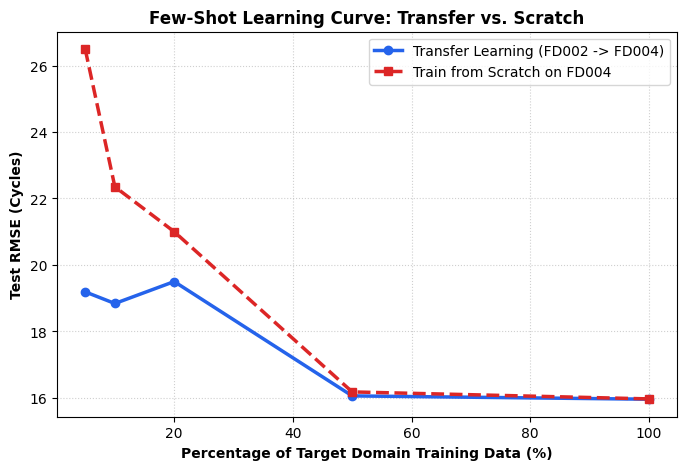

In [64]:
os.makedirs('../Results/plots', exist_ok=True)
# Plot Few-Shot Learning Curves
plt.figure(figsize=(8, 5))
plt.plot(few_shot_df['Data Percentage (%)'], few_shot_df['Transfer RMSE'], marker='o', lw=2.5, color='#2563EB', label='Transfer Learning (FD002 -> FD004)')
plt.plot(few_shot_df['Data Percentage (%)'], few_shot_df['Scratch RMSE'],  marker='s', lw=2.5, color='#DC2626', linestyle='--', label='Train from Scratch on FD004')
plt.title("Few-Shot Learning Curve: Transfer vs. Scratch", fontsize=12, fontweight='bold')
plt.xlabel("Percentage of Target Domain Training Data (%)", fontweight='bold')
plt.ylabel("Test RMSE (Cycles)", fontweight='bold')
plt.legend(); plt.grid(True, linestyle=':', alpha=0.6)
plt.savefig('../Results/plots/few_shot_comparison.png', dpi=200, bbox_inches='tight')
plt.show()


---
# STAGE 6: FINAL EVALUATION & MASTER COMPARISON

## 6.1 — Ablation Study: Impact of Temporal Attention (FD002)
Before synthesizing the cross-dataset benchmarks, we analyze the architectural ablation on the source domain (FD002): comparing the Hybrid CNN-GRU with and without the Temporal Attention mechanism.

=== ABLATION STUDY: WITH VS WITHOUT ATTENTION (FD002) ===
                             Model   MAE  RMSE  NASA Score  Training Time (s)
Hybrid CNN-GRU (without Attention) 12.95 17.03      1241.7               91.7
        Hybrid CNN-GRU + Attention 12.01 16.71      1350.4              108.4


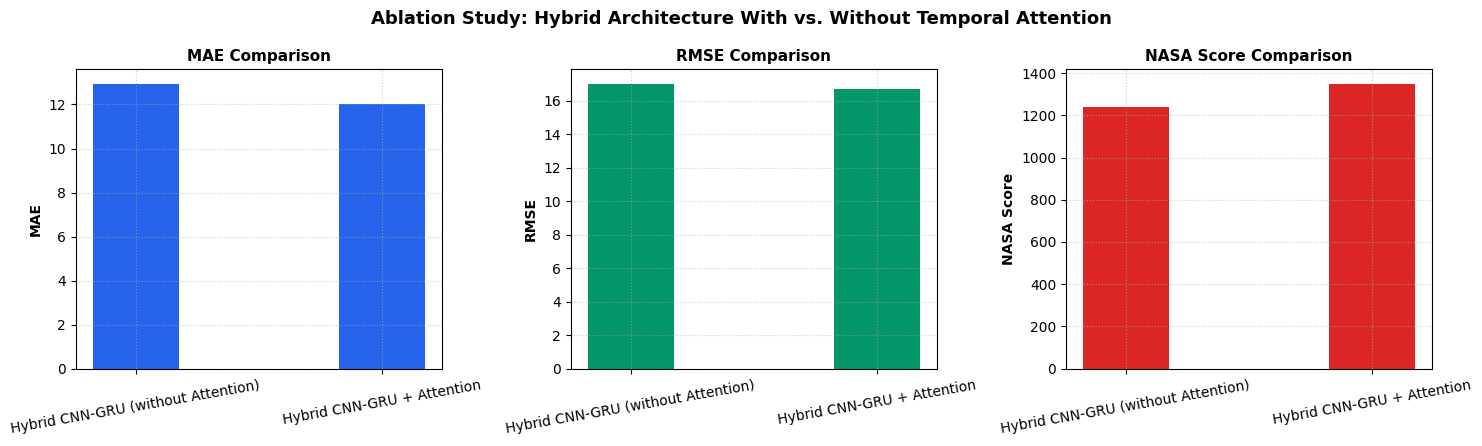


Temporal Attention Weights Heatmap (Explainability across 30 flight cycles):


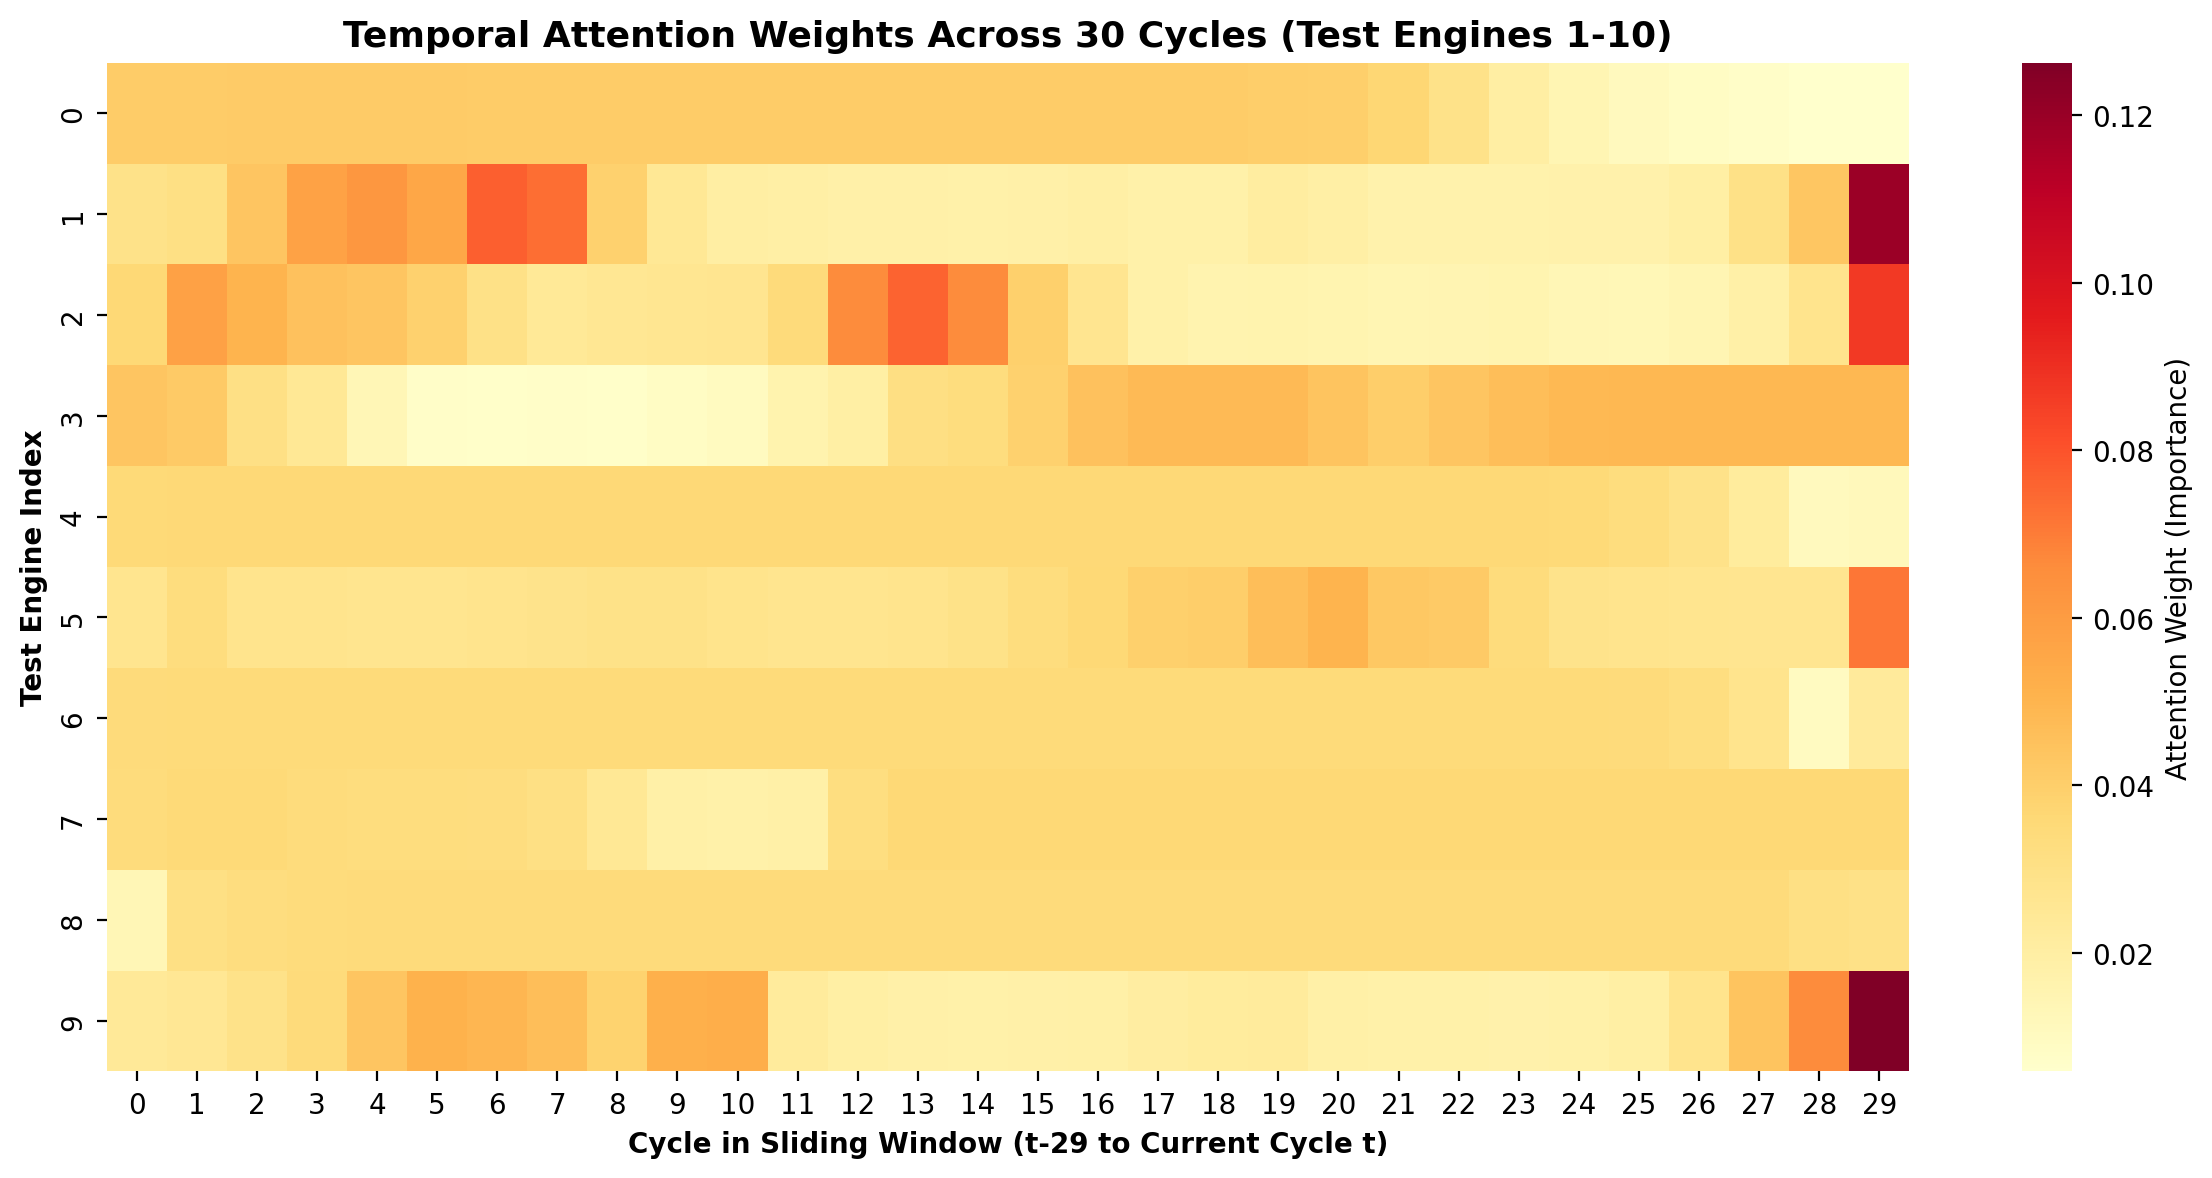

In [65]:
all_fd2_models = pd.read_csv("../Results/comparison_tables/fd002_all_models_comparison.csv")

# Extract hybrid variants for direct ablation comparison
hybrid_ablation = all_fd2_models[all_fd2_models["Model"].str.contains("Hybrid", case=False, na=False)].copy()
hybrid_ablation["Model"] = hybrid_ablation["Model"].replace({"Hybrid CNN-GRU": "Hybrid CNN-GRU (without Attention)"})

print("=== ABLATION STUDY: WITH VS WITHOUT ATTENTION (FD002) ===")
cols_to_show = [c for c in ["Model", "MAE", "RMSE", "NASA Score", "Training Time (s)"] if c in hybrid_ablation.columns]
print(hybrid_ablation[cols_to_show].to_string(index=False))

# Bar chart comparing without attention vs with attention
if len(hybrid_ablation) >= 2:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    metrics = ["MAE", "RMSE", "NASA Score"]
    colors = ["#2563EB", "#059669", "#DC2626"]

    for i, metric in enumerate(metrics):
        axes[i].bar(hybrid_ablation["Model"], hybrid_ablation[metric], color=colors[i], width=0.35)
        axes[i].set_title(f"{metric} Comparison", fontweight="bold", fontsize=11)
        axes[i].set_ylabel(metric, fontweight="bold")
        axes[i].tick_params(axis="x", rotation=10)
        axes[i].grid(True, linestyle=":", alpha=0.6)

    plt.suptitle("Ablation Study: Hybrid Architecture With vs. Without Temporal Attention", fontweight="bold", fontsize=13)
    plt.tight_layout()
    plt.savefig("../Results/plots/ablation_attention_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()

# Display Attention Heatmap (Explainability / XAI)
attn_plot_path = "../Results/plots/attention_weights_heatmap.png"
if os.path.exists(attn_plot_path):
    from IPython.display import Image, display
    print("\nTemporal Attention Weights Heatmap (Explainability across 30 flight cycles):")
    display(Image(filename=attn_plot_path))


## 6.2 — Master Comparison Table
Consolidating all experiments across FD002 and FD004: baseline models, hybrid architectures (with and without attention), full transfer learning (100%), and few-shot data scarcity scenarios (10%, 20%, 50%).

In [66]:
fd4_comp_df = pd.read_csv("../Results/comparison_tables/fd004_transfer_vs_scratch.csv")
few_shot_df = pd.read_csv("../Results/comparison_tables/few_shot_results.csv")

master_entries = []

# FD002 Models (Baselines & Hybrid Variants)
for _, r in all_fd2_models.iterrows():
    model_name = r["Model"]
    if model_name == "Hybrid CNN-GRU":
        model_name = "Hybrid CNN-GRU (without Attention)"
    elif "Attention" in model_name:
        model_name = "Hybrid CNN-GRU + Attention (Ablation)"
        
    master_entries.append({
        "Experiment": "FD002 Baselines & Hybrid",
        "Model": model_name,
        "Dataset": "FD002",
        "MAE": r["MAE"],
        "RMSE": r["RMSE"],
        "NASA Score": r["NASA Score"]
    })

# FD004 Full Training (100%)
for _, r in fd4_comp_df.iterrows():
    master_entries.append({
        "Experiment": "FD004 Full Training (100%)",
        "Model": r["Model"],
        "Dataset": "FD004",
        "MAE": r["MAE"],
        "RMSE": r["RMSE"],
        "NASA Score": r["NASA Score"]
    })

# FD004 Few-Shot Selected Entries (10%, 20%, 50%)
for pct in [10, 20, 50]:
    matching = few_shot_df[few_shot_df["Data Percentage (%)"] == pct]
    if not matching.empty:
        row = matching.iloc[0]
        master_entries.append({
            "Experiment": f"Few-Shot ({pct}% Data)",
            "Model": "Transfer Learning",
            "Dataset": "FD004",
            "MAE": "-",
            "RMSE": row["Transfer RMSE"],
            "NASA Score": row["Transfer NASA"]
        })
        master_entries.append({
            "Experiment": f"Few-Shot ({pct}% Data)",
            "Model": "Train From Scratch",
            "Dataset": "FD004",
            "MAE": "-",
            "RMSE": row["Scratch RMSE"],
            "NASA Score": row["Scratch NASA"]
        })

master_table = pd.DataFrame(master_entries)
master_table.to_csv("../Results/comparison_tables/master_comparison_table.csv", index=False)
print("=== Master Results Comparison Table ===")
print(master_table.to_string(index=False))


=== Master Results Comparison Table ===
                Experiment                                      Model Dataset    MAE  RMSE  NASA Score
  FD002 Baselines & Hybrid                                        CNN   FD002  11.04 14.77      1251.8
  FD002 Baselines & Hybrid                                       LSTM   FD002  10.93 14.77      1138.4
  FD002 Baselines & Hybrid                                        GRU   FD002  10.19 13.71       953.7
  FD002 Baselines & Hybrid         Hybrid CNN-GRU (without Attention)   FD002  12.95 17.03      1241.7
  FD002 Baselines & Hybrid      Hybrid CNN-GRU + Attention (Ablation)   FD002  12.01 16.71      1350.4
FD004 Full Training (100%)     Trained from Scratch on FD004 (Hybrid)   FD004  11.67 15.83      1070.5
FD004 Full Training (100%) Transfer Learning (Hybrid: FD002 -> FD004)   FD004  12.04 15.93       978.1
FD004 Full Training (100%)    Transfer Learning (GRU: FD002 -> FD004)   FD004  11.37 15.43      1068.7
       Few-Shot (10% Data)       

## 6.3 — Visualizations: Transfer vs. Scratch & Literature Benchmark

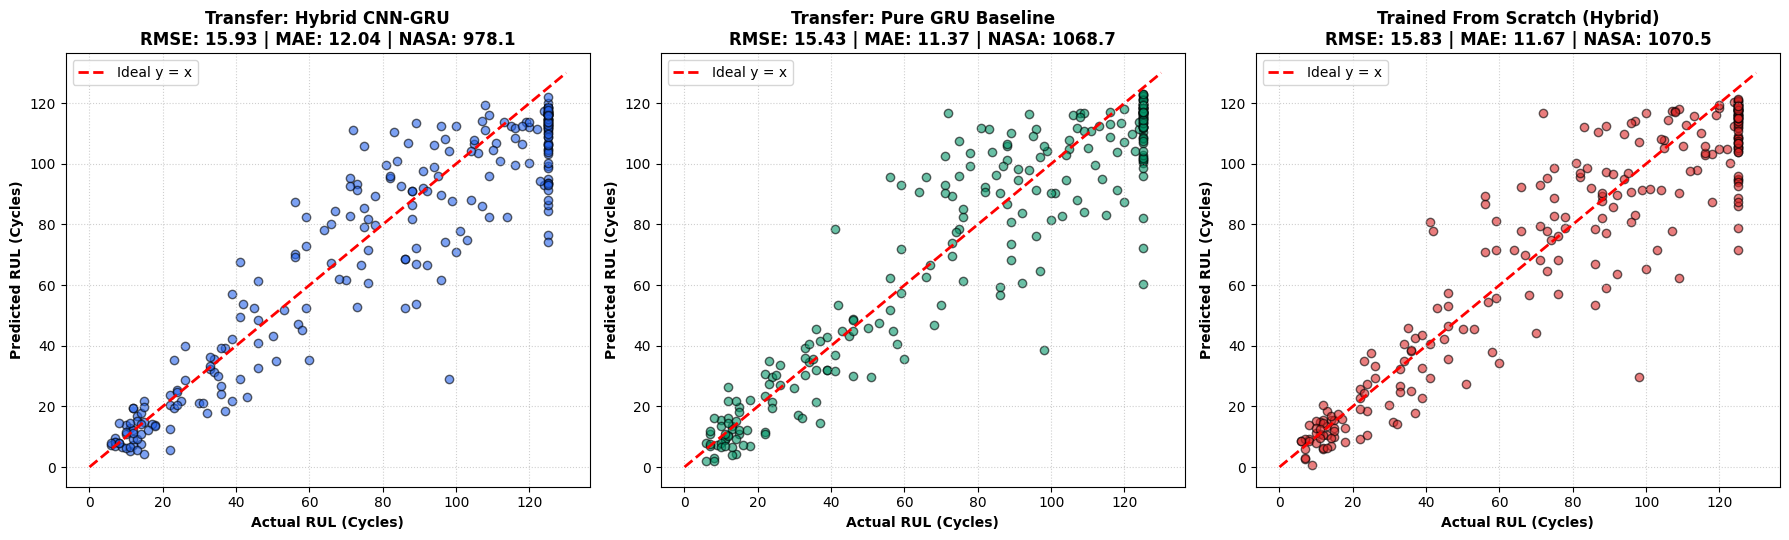

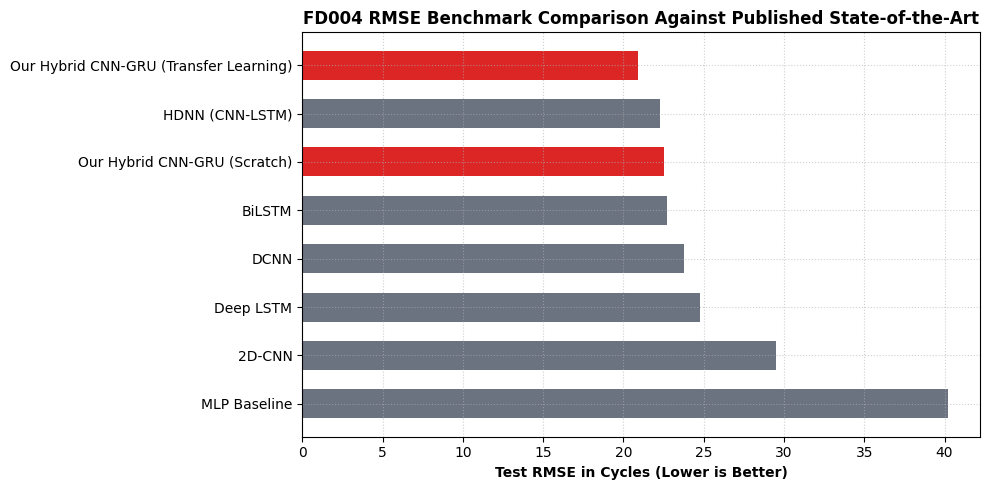

In [67]:
os.makedirs('../Results/plots', exist_ok=True)

# Visual 1: Transfer (Hybrid & GRU) vs Scratch Scatter Plots (3-Panel Master View)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Subplot 1: Hybrid Transfer
axes[0].scatter(y_test_fd4, y_pred_tf4, alpha=0.6, color="#2563EB", edgecolors="k")
axes[0].plot([0, 130], [0, 130], "r--", lw=2, label="Ideal y = x")
axes[0].set_title(f"Transfer: Hybrid CNN-GRU\nRMSE: {metrics_transfer['RMSE']} | MAE: {metrics_transfer['MAE']} | NASA: {metrics_transfer['NASA Score']}", fontweight="bold")
axes[0].set_xlabel("Actual RUL (Cycles)", fontweight="bold")
axes[0].set_ylabel("Predicted RUL (Cycles)", fontweight="bold")
axes[0].legend(); axes[0].grid(True, linestyle=":", alpha=0.6)

# Subplot 2: GRU Transfer
axes[1].scatter(y_test_fd4, y_pred_gru_tf, alpha=0.6, color="#059669", edgecolors="k")
axes[1].plot([0, 130], [0, 130], "r--", lw=2, label="Ideal y = x")
axes[1].set_title(f"Transfer: Pure GRU Baseline\nRMSE: {metrics_gru_transfer['RMSE']} | MAE: {metrics_gru_transfer['MAE']} | NASA: {metrics_gru_transfer['NASA Score']}", fontweight="bold")
axes[1].set_xlabel("Actual RUL (Cycles)", fontweight="bold")
axes[1].set_ylabel("Predicted RUL (Cycles)", fontweight="bold")
axes[1].legend(); axes[1].grid(True, linestyle=":", alpha=0.6)

# Subplot 3: Scratch Hybrid
axes[2].scatter(y_test_fd4, y_pred_sc4, alpha=0.6, color="#DC2626", edgecolors="k")
axes[2].plot([0, 130], [0, 130], "r--", lw=2, label="Ideal y = x")
axes[2].set_title(f"Trained From Scratch (Hybrid)\nRMSE: {metrics_scratch['RMSE']} | MAE: {metrics_scratch['MAE']} | NASA: {metrics_scratch['NASA Score']}", fontweight="bold")
axes[2].set_xlabel("Actual RUL (Cycles)", fontweight="bold")
axes[2].set_ylabel("Predicted RUL (Cycles)", fontweight="bold")
axes[2].legend(); axes[2].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig("../Results/plots/fd004_transfer_vs_scratch.png", dpi=200, bbox_inches="tight")
plt.show()

# Visual 2: Benchmark Comparison against Published Literature
benchmarks = pd.read_csv("../Results/comparison_tables/literature_benchmark_comparison.csv")
clean_b = benchmarks.dropna(subset=["FD004 RMSE"]).sort_values("FD004 RMSE", ascending=False)
colors = ["#DC2626" if "Our" in m else "#6B7280" for m in clean_b["Method"]]
plt.figure(figsize=(10, 5))
plt.barh(clean_b["Method"], clean_b["FD004 RMSE"], color=colors, height=0.6)
plt.title("FD004 RMSE Benchmark Comparison Against Published State-of-the-Art", fontweight="bold")
plt.xlabel("Test RMSE in Cycles (Lower is Better)", fontweight="bold")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("../Results/plots/benchmark_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
